# Fashion Deep Learning Recommendation Systems

*Download the Dataset from here <a href=https://www.kaggle.com/datasets/paramaggarwal/fashion-product-images-small>Dataset</a>
All the code is given. You need to download the data and train the model using the following code and save the model. Then, create a streamlit app to recommend similar products.

<img src='dataset-cover.png'>

In [45]:
import numpy as np
import pickle as pkl
import tensorflow as tf
from tensorflow.keras.applications.resnet50 import ResNet50,preprocess_input
from tensorflow.keras.preprocessing import image
from tensorflow.keras.layers import GlobalMaxPool2D

from sklearn.neighbors import NearestNeighbors
import os
from numpy.linalg import norm
import warnings
warnings.filterwarnings("ignore")

In [2]:
#Extract Filenames from Folder

In [3]:
filenames = []
for file in os.listdir('images'):
    filenames.append(os.path.join('images',file))
    

In [4]:
len(filenames)

44441

In [5]:
#Importing ResNet50 Model and Cofiguration

In [6]:
model = ResNet50(weights='imagenet', include_top=False, input_shape=(160,160,3))
model.trainable = False

model = tf.keras.models.Sequential([model,
                                   GlobalMaxPool2D()
                                   ])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)                │ (None, 5, 5, 2048)          │      23,587,712 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_max_pooling2d                 │ (None, 2048)                │               0 │
│ (GlobalMaxPooling2D)                 │                             │                 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 23,587,712 (89.98 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 23,587,712 (89.98 MB)

In [7]:
#Extracting Fetaures from Image

In [8]:
def extract_features_from_images(image_path, model):
    img = image.load_img(image_path, target_size=(160,160))
    img_array = image.img_to_array(img)
    img_expand_dim = np.expand_dims(img_array, axis=0)
    img_preprocess = preprocess_input(img_expand_dim)
    result = model.predict(img_preprocess, verbose=0).flatten()
    norm_result = result/norm(result)
    return norm_result

In [9]:
extract_features_from_images(filenames[0], model)

array([0.00243007, 0.02699807, 0.00685795, ..., 0.00206076, 0.02256775,
       0.07967659], shape=(2048,), dtype=float32)

In [10]:
image_features = []
for file in filenames:
    image_features.append(extract_features_from_images(file, model))
image_features

[array([0.00243007, 0.02699807, 0.00685795, ..., 0.00206076, 0.02256775,
        0.07967659], shape=(2048,), dtype=float32),
 array([0.        , 0.02970171, 0.00538261, ..., 0.        , 0.        ,
        0.07157836], shape=(2048,), dtype=float32),
 array([0.        , 0.03010744, 0.01152079, ..., 0.        , 0.        ,
        0.05538022], shape=(2048,), dtype=float32),
 array([0.        , 0.05261476, 0.01214573, ..., 0.0020935 , 0.04146739,
        0.04888803], shape=(2048,), dtype=float32),
 array([0.        , 0.05630806, 0.        , ..., 0.0040488 , 0.0136589 ,
        0.04169129], shape=(2048,), dtype=float32),
 array([0.        , 0.09677274, 0.        , ..., 0.00327737, 0.00557144,
        0.03131386], shape=(2048,), dtype=float32),
 array([0.        , 0.08983973, 0.        , ..., 0.        , 0.03863792,
        0.08481471], shape=(2048,), dtype=float32),
 array([0.        , 0.06871168, 0.00196588, ..., 0.00046358, 0.00064587,
        0.02835543], shape=(2048,), dtype=float32),


In [60]:
#Save pickle
with open("Image_features.pkl", "wb") as f:
    pkl.dump(image_features, f, protocol=4)

with open("filenames.pkl", "wb") as f:
    pkl.dump(filenames, f, protocol=4)

In [61]:
#Loading Pickle Files

In [62]:
with open("Image_features.pkl", "rb") as f:
    image_features = pkl.load(f)

with open("filenames.pkl", "rb") as f:
    filenames = pkl.load(f)

In [63]:
np.array(Image_features).shape

(44441, 2048)

In [64]:
#Finidng Simialar Images

In [65]:
neighbors = NearestNeighbors(n_neighbors=6, algorithm='brute', metric='euclidean')

In [66]:
neighbors.fit(Image_features)

,n_neighbors,6
,radius,1.0
,algorithm,'brute'
,leaf_size,30
,metric,'euclidean'
,p,2
,metric_params,None
,n_jobs,None


In [67]:
input_image = extract_features_from_images('images/16871.jpg', model)

In [68]:
distance,indices = neighbors.kneighbors([input_image])

In [69]:
indices[0]

array([ 5828, 23502,  5799,  5814,  6257,  6268])

In [70]:
from IPython.display import Image

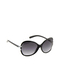

In [71]:
Image('images/16871.jpg')

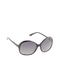

In [72]:
Image(filenames[indices[0][1]])

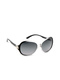

In [73]:
Image(filenames[indices[0][2]])

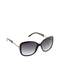

In [74]:
Image(filenames[indices[0][3]])

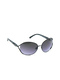

In [75]:
Image(filenames[indices[0][4]])

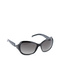

In [76]:
Image(filenames[indices[0][5]])

In [78]:
model.save('resnet_feature_extractor.keras')